# Import right dependencies

In [3]:
import numpy as np
import h5py
import cv2
import numpy
import matplotlib.pyplot as plt
from keras.utils import to_categorical
from keras.datasets import mnist
from sklearn.metrics import classification_report, confusion_matrix

# Import dataset

In [4]:
(train_X, train_y), (test_X, test_y) = mnist.load_data()
print(train_X.shape)
print(train_y.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
(60000, 28, 28)
(60000,)


# One hot encode train and test labels

In [56]:
train_y_one_hot= to_categorical(train_y)
train_y_one_hot = np.einsum('vz->zv', train_y_one_hot)
test_y_one_hot= to_categorical(test_y)
test_y_one_hot = np.einsum('vz->zv', test_y_one_hot)
print(train_X.shape)
print(train_y_one_hot.shape)

(60000, 28, 28)
(10, 60000)


# Flatten and reshape train and test inputs

In [7]:
train_x_flatten = train_X.reshape(train_X.shape[0], -1).T   # The "-1" makes reshape flatten the remaining dimensions
test_x_flatten = test_X.reshape(test_X.shape[0], -1).T

# Standardize data to have feature values between 0 and 1.
train_x = train_x_flatten/255.
test_x = test_x_flatten/255.

print ("train_x's shape: " + str(train_x.shape))
print ("test_x's shape: " + str(test_x.shape))

train_x's shape: (784, 60000)
test_x's shape: (784, 10000)


# Define neural network architecture

In [8]:
#input dymension, hidden_layers
layers_dims = [784, 30, 20, 15, 10]

# Define activation functions

In [9]:
def relu(z):
    A = np.maximum(0, z)
    cache = z
    return A, cache

In [10]:
def sigmoid(z):
    s = 1/ (1+ np.exp(-z))
    cache = z
    return s, cache

In [11]:
def softmax(z):
    cache = z 
    z_norm = z - np.max(z)
    exp = np.exp(z_norm)
    exp = exp / np.sum(exp, axis=0, keepdims=True)
    return exp, cache

In [12]:
print(relu(np.array([-2, 0, 3])))
print(sigmoid(np.array([-2, 0, 3])))
print(softmax(np.array([[1], [2], [3]]))[0])

(array([0, 0, 3]), array([-2,  0,  3]))
(array([0.11920292, 0.5       , 0.95257413]), array([-2,  0,  3]))
[[0.09003057]
 [0.24472847]
 [0.66524096]]


In [13]:
def initialize_parameters_deep(layer_dims):
    np.random.seed(1)
    parameters = {}
    L = len(layer_dims)            # number of layers in the network

    for l in range(1, L):
        parameters['W' + str(l)] = np.random.randn(layer_dims[l], layer_dims[l-1]) / np.sqrt(layer_dims[l-1])
        parameters['b' + str(l)] = np.zeros((layer_dims[l], 1))

    return parameters

In [14]:
def linear_forward(A, W, b):
    Z = np.dot(W, A)+b
    cache = (A, W, b)
    return Z, cache

In [16]:
def linear_activation_forward(A_prev, W, b, activation):
    if activation == "sigmoid":
        Z, linear_cache = linear_forward(A_prev, W, b)
        A, activation_cache = sigmoid(Z) 
    
    elif activation == "softmax":
        Z, linear_cache = linear_forward(A_prev, W, b)
        A, activation_cache = softmax(Z)
    
    elif activation == "relu":
        Z, linear_cache = linear_forward(A_prev, W, b)
        A, activation_cache = relu(Z)
    cache = (linear_cache, activation_cache)

    return A, cache

# Define model forward function

In [17]:
def L_model_forward(X, parameters):
    caches = []
    A = X
    L = len(parameters) // 2            

    for l in range(1, L):
        A_prev = A 
        A, cache = linear_activation_forward(A_prev, parameters['W' + str(l)], parameters['b' + str(l)], "relu")
        caches.append(cache)
    
    AL, cache = linear_activation_forward(A, parameters['W' + str(L)], parameters['b' + str(L)], "softmax")
    caches.append(cache)
    
    return AL, caches

In [19]:
parameters = initialize_parameters_deep(layers_dims)

for key, value in parameters.items():
    print(key, value.shape)

W1 (30, 784)
b1 (30, 1)
W2 (20, 30)
b2 (20, 1)
W3 (15, 20)
b3 (15, 1)
W4 (10, 15)
b4 (10, 1)


# Define cost functions

In [18]:
def compute_cost(AL, Y):
    m = Y.shape[1]
    cost = -np.mean(Y * np.log(AL))
    cost = np.squeeze(cost)
    return cost

# Define activation function derivatives with respect to loss

In [25]:
def sigmoid_backward(dA, cache):
    Z = cache 
    s = 1/ (1+ np.exp(-Z))
    dZ = dA * s * (1-s)
    return dZ

In [26]:
def relu_backward(dA, cache):
    Z = cache
    dZ = np.array(dA, copy=True) 
    dZ[Z <= 0] = 0
    return dZ

# Define backward propagation functions

In [27]:
def linear_backward(dZ, cache):
    A_prev, W, b = cache
    m = A_prev.shape[1]
    dW = np.multiply(1/m,np.dot(dZ, A_prev.transpose()))
    db = np.multiply(1/m,np.sum(dZ, axis = 1, keepdims = True))
    dA_prev = np.dot(W.transpose(),dZ)

    return dA_prev, dW, db

In [28]:
def linear_activation_backward(dA, cache, activation):

    linear_cache, activation_cache = cache
    
    if activation == "relu":
        dZ = relu_backward(dA, activation_cache)
        dA_prev, dW, db = linear_backward(dZ, linear_cache)

    elif activation == "softmax":
        dA_prev, dW, db = linear_backward(dA, linear_cache)

    elif activation == "sigmoid":
        dZ = sigmoid_backward(dA, activation_cache)
        dA_prev, dW, db = linear_backward(dZ, linear_cache)
    
    return dA_prev, dW, db

# Define model backward function

In [29]:
def L_model_backward(AL, Y, caches):

    grads = {}
    L = len(caches) # the number of layers
    m = AL.shape[1]
    Y = Y.reshape(AL.shape)
    
    dAL = (AL - Y)
    
    current_cache = caches[L-1]
    dA_prev_temp, dW_temp, db_temp = linear_activation_backward(
        dAL, current_cache, "softmax"
    )
    grads["dA" + str(L-1)] = dA_prev_temp
    grads["dW" + str(L)] = dW_temp
    grads["db" + str(L)] = db_temp
    
    for l in reversed(range(L-1)):
        current_cache = caches[l]
        dA_prev_temp, dW_temp, db_temp = linear_activation_backward(
            grads["dA" + str(l+1)], current_cache, "relu"
        )
        grads["dA" + str(l)] = dA_prev_temp
        grads["dW" + str(l+1)] = dW_temp
        grads["db" + str(l+1)] = db_temp

    return grads

In [30]:
def update_parameters(params, grads, learning_rate):
    parameters = params.copy()
    L = len(parameters) // 2 
    for l in range(L):
        parameters["W" + str(l+1)] = params["W" + str(l+1)] - learning_rate * grads["dW" + str(l+1)]
        parameters["b" + str(l+1)] = params["b" + str(l+1)]- learning_rate * grads["db" + str(l+1)]

    return parameters

# Define model

In [31]:
def L_layer_model(X, Y, layers_dims, learning_rate = 0.9, num_iterations = 3000, print_cost=False):

    np.random.seed(1)
    costs = []                         # keep track of cost
    parameters = initialize_parameters_deep(layers_dims)

    for i in range(0, num_iterations):
        AL, caches = L_model_forward(X, parameters)
        cost = compute_cost(AL, Y)
        grads = L_model_backward(AL, Y, caches)
        parameters = update_parameters(parameters, grads, learning_rate)
                
        # Print the cost every 100 iterations
        if print_cost and i % 100 == 0 or i == num_iterations - 1:
            print("Cost after iteration {}: {}".format(i, np.squeeze(cost)))
        if i % 100 == 0 or i == num_iterations:
            costs.append(cost)
    
    return parameters, costs

# Train model

In [32]:
parameters, costs = L_layer_model(train_x, train_y_one_hot, layers_dims, num_iterations=5000, print_cost=True)

Cost after iteration 0: 0.23168352039847223
Cost after iteration 100: 0.06344531935787653
Cost after iteration 200: 0.032546605076804576
Cost after iteration 300: 0.024558174291210294
Cost after iteration 400: 0.021617040134226367
Cost after iteration 500: 0.025113203098085204
Cost after iteration 600: 0.017880805455758538
Cost after iteration 700: 0.04273168816967817
Cost after iteration 800: 0.0225205321064286
Cost after iteration 900: 0.018089945449494656
Cost after iteration 1000: 0.016852686869388185
Cost after iteration 1100: 0.015535484273417909
Cost after iteration 1200: 0.02826051614845912
Cost after iteration 1300: 0.022244213192819263
Cost after iteration 1400: 0.01945072904803019
Cost after iteration 1500: 0.041066564476952526
Cost after iteration 1600: 0.018472231312696947
Cost after iteration 1700: 0.018653444078590684
Cost after iteration 1800: 0.016530032059134447
Cost after iteration 1900: 0.03855232877604006
Cost after iteration 2000: 0.02116603751849972
Cost after it

# Define function for predictions and their accuracy

In [33]:
def predict(X, y, parameters):
    m = X.shape[1]
    n = len(parameters) // 2
    p = np.zeros((1,m))
    
    probas, caches = L_model_forward(X, parameters)
    return np.argmax(probas, axis=0)    

In [34]:
def accuracy(y, y_hat):
    acc = np.sum(y==y_hat)/len(y)
    return acc

# Make predictions on training data, get accuracy

In [35]:
pred_train = predict(train_x, train_y, parameters)

In [36]:
accuracy(train_y, pred_train)

np.float64(0.94805)

In [37]:
pred_test = predict(test_x, test_y, parameters)

accuracy(test_y, pred_test)

np.float64(0.9383)

# Print confusion matrix and classification report for train predictions

In [40]:
print(confusion_matrix(train_y, pred_train))
print(classification_report(train_y, pred_train))

[[5808    2   11    1   19    9   28    1   39    5]
 [   2 6590   62    8   18    3    3   18   33    5]
 [  27   26 5633   45   53    4   32   27  108    3]
 [  24   32  191 5542    8   71    6   66  150   41]
 [  13   13   41    0 5656    3   43    8    8   57]
 [  69    5   28   76   47 4866  123    3  175   29]
 [  47    6   26    0   29   23 5759    0   28    0]
 [  10   20   67    6   66    3    0 6035    9   49]
 [  42   39   70   44   14   48   43    7 5517   27]
 [  40    8    9   38  211   14    3   86   63 5477]]
              precision    recall  f1-score   support

           0       0.95      0.98      0.97      5923
           1       0.98      0.98      0.98      6742
           2       0.92      0.95      0.93      5958
           3       0.96      0.90      0.93      6131
           4       0.92      0.97      0.95      5842
           5       0.96      0.90      0.93      5421
           6       0.95      0.97      0.96      5918
           7       0.97      0.96   

# Make predictions on test data, get accuracy

In [39]:
pred_test = predict(test_x, test_y, parameters)

# Print confusion matrix and classification report for test predictions

In [41]:
print(confusion_matrix(test_y, pred_test))
print(classification_report(test_y, pred_test))

[[ 960    0    4    1    3    0    5    2    4    1]
 [   0 1116    8    2    1    1    0    2    5    0]
 [   9    4  958   13    9    1    7    7   24    0]
 [   4    4   37  904    3   12    1   11   28    6]
 [   1    2    8    0  938    2   11    2    3   15]
 [  11    2    3   13    7  793   21    3   31    8]
 [   9    2    3    1    5    5  928    0    5    0]
 [   2    6   22    5    6    0    0  972    2   13]
 [  13    5   16    6    7   14    8    5  895    5]
 [   8    5    1    6   32    5    1   13   19  919]]
              precision    recall  f1-score   support

           0       0.94      0.98      0.96       980
           1       0.97      0.98      0.98      1135
           2       0.90      0.93      0.92      1032
           3       0.95      0.90      0.92      1010
           4       0.93      0.96      0.94       982
           5       0.95      0.89      0.92       892
           6       0.95      0.97      0.96       958
           7       0.96      0.95   

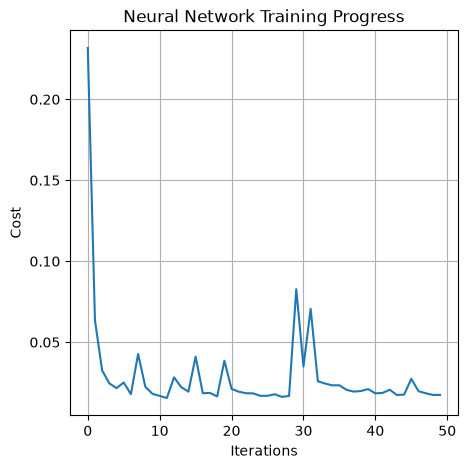

In [54]:
plt.figure(figsize=(5, 5))

plt.plot(costs)

plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Neural Network Training Progress")
plt.grid()
plt.show()

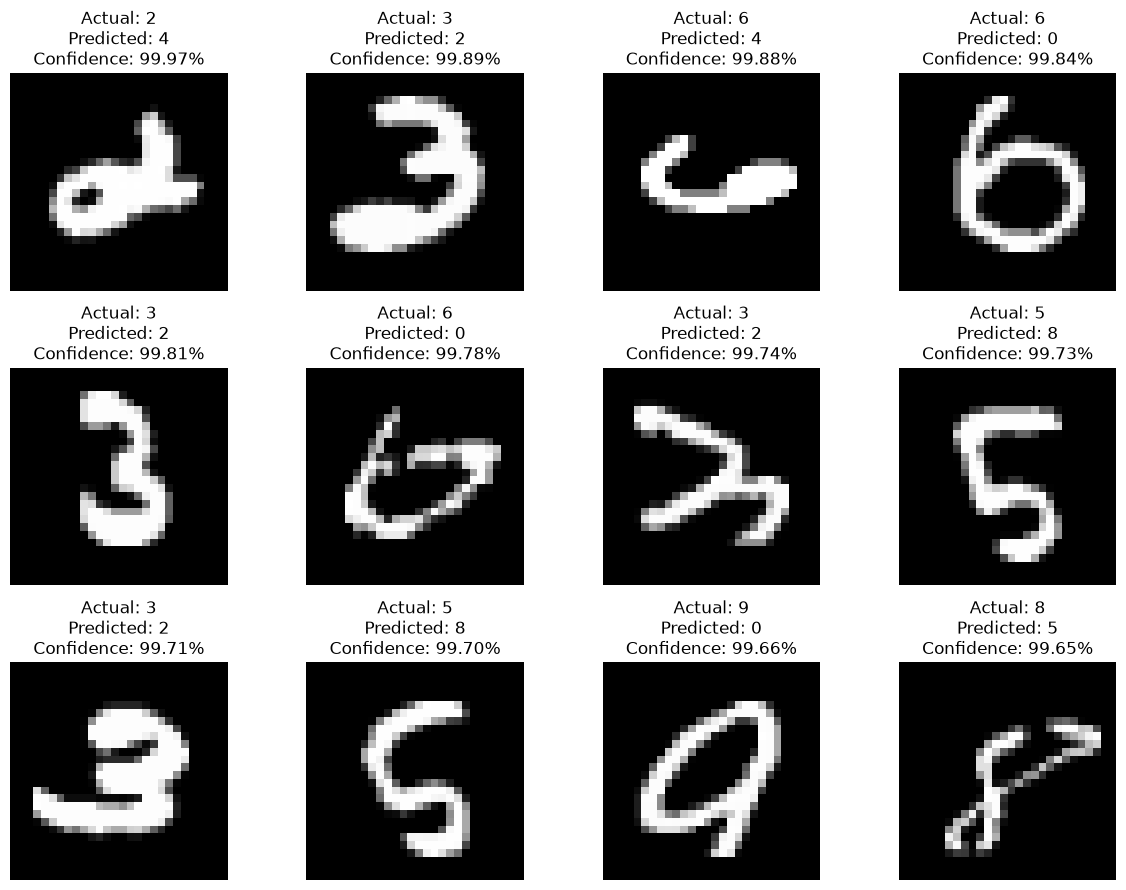

In [55]:

test_probabilities, _ = L_model_forward(test_x, parameters)             # most confidently incorrect predictions
confidence = np.max(test_probabilities, axis=0)
wrong_indices = np.where(pred_test != test_y)[0]
# Sorting incorrect predictions by confidence to check and ranking highest first
sorted_wrong = wrong_indices[
    np.argsort(confidence[wrong_indices])[::-1]
]

fig, axes = plt.subplots(3, 4, figsize=(12, 9))   #checking only 12

for ax, idx in zip(axes.flat, sorted_wrong[:12]):
    ax.imshow(test_X[idx], cmap='gray')
    ax.set_title(
        f"Actual: {test_y[idx]}\n"
        f"Predicted: {pred_test[idx]}\n"
        f"Confidence: {confidence[idx]:.2%}"
    )
    ax.axis('off')

plt.tight_layout()
plt.show()

# Plot part of the incorrectly predicted images and append them to list



In [42]:
fig = plt.figure(figsize=(15,200))
z = 0
incorrect_list = []
for i in range(len(test_y)):
    y = test_y[i]
    y_hat = pred_test[i]
    if y != y_hat:
        z+=1
        incorrect_list.append(i)
        ax = fig.add_subplot(100, 8, z)
        ax.imshow(test_X[i], cmap=plt.get_cmap('gray'))
        
        ax.set_title('y: {y}/ y_hat: {y_hat}'
                     .format(y=test_y[i], y_hat=pred_test[i]))
        plt.axis('off')

# Define function for getting derivative of loss with respect to input for saliency maps

In [43]:
def get_saliency_map(X, y, parameters):
    m = X.shape[1]
    n = len(parameters) // 2
    p = np.zeros((1,m))
    
    probas, caches = L_model_forward(X, parameters)
    cost = compute_cost(probas, y)
    grads = L_model_backward(probas, y, caches)
    dy_dx = grads["dA0"]

    return np.argmax(probas, axis=0), dy_dx

# Prepare incorrectly predicted data for saliency maps 

In [45]:
saliency_test = test_x[:, incorrect_list]
saliency_test.reshape(saliency_test.shape[0],len(incorrect_list))
print(saliency_test.shape)

saliency_test_y = test_y[incorrect_list]
print(saliency_test_y.shape)

test_y_one_hot_for_saliency = to_categorical(saliency_test_y)
test_y_one_hot_for_saliency = np.einsum('vz->zv', test_y_one_hot_for_saliency)

(784, 617)
(617,)


# Get predictions and derivative of loss with respect to input

In [46]:
probas, dy_dx = get_saliency_map(saliency_test, test_y_one_hot_for_saliency, parameters)

# Reshape and normalize results for plot 

In [47]:
dy_dx_one_rs = dy_dx.reshape(28,28,dy_dx.shape[1])

normalized_tensor = np.multiply(
    255, (((dy_dx_one_rs - np.min(dy_dx_one_rs))
    / (np.max(dy_dx_one_rs) - np.min(dy_dx_one_rs)))))

# Apply penalty for smaller values

In [48]:
log = (1/(1+np.log((np.max(normalized_tensor) - normalized_tensor + 0.0001))))
normalized_tensor_weighted = np.multiply(normalized_tensor,log)

# The brightest points show the highest impact on loss

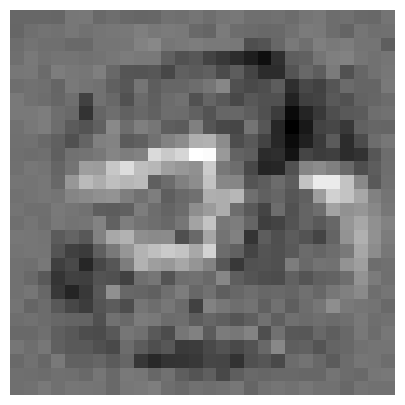

In [50]:
plt.figure(figsize=(5, 5))
plt.axis('off')
plt.imshow(normalized_tensor_weighted[:,:,1], cmap='gray')
plt.show()

# Darken the prediction images so saliency points become the brightest ones in image

In [51]:
saliency_test = test_x[:, incorrect_list]
saliency_test.reshape(saliency_test.shape[0],len(incorrect_list))
saliency_test = saliency_test.reshape(28,28,saliency_test.shape[1])
saliency_test = np.multiply(
    20, (saliency_test - np.min(saliency_test))
    / (np.max(saliency_test) - np.min(saliency_test))
)

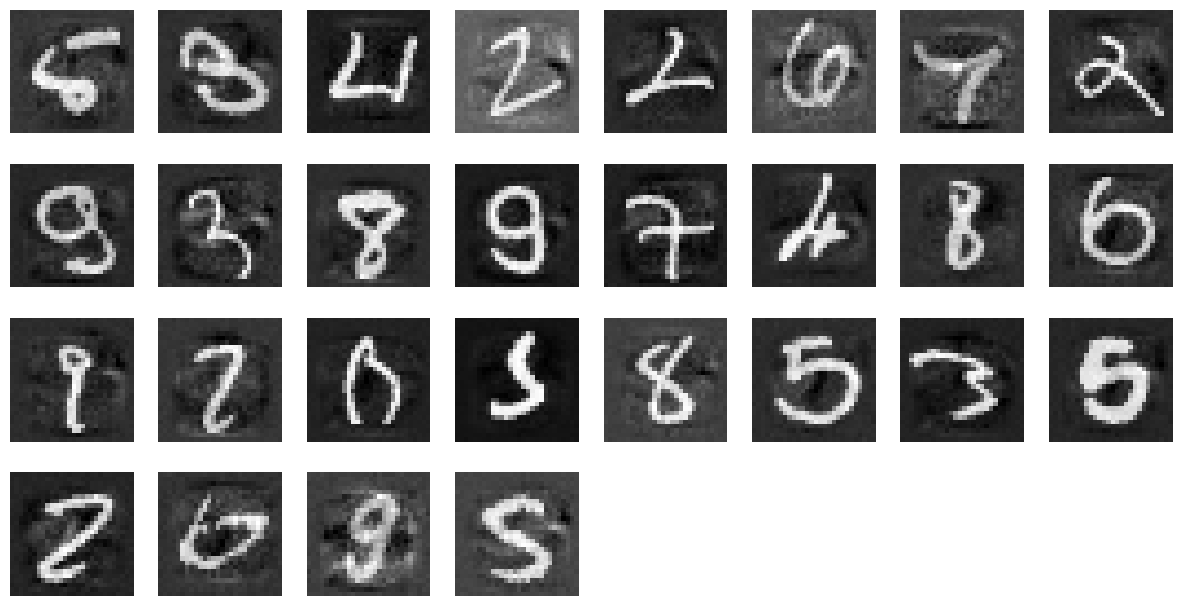

In [57]:
fig = plt.figure(figsize=(15,200))
z = 0
for i in range(saliency_test.shape[1]):
    z += 1
    picture_i = saliency_test[:,:,i]
    saliency_map_i = normalized_tensor_weighted[:,:,i]
    ax = fig.add_subplot(100, 8, z)
    super_imposed = cv2.addWeighted(picture_i, 0.5, saliency_map_i, 0.5, 0.0, dtype=cv2.CV_64F)
    ax.imshow(super_imposed, cmap=plt.get_cmap('gray'))
    
    plt.axis('off')
plt.show()

# Observation

In this exercise i implemented a feedforward neural network from scratch using Python and NumPy to classify handwritten digits from the MNIST dataset. Network consists of an input layer with 784 features, three hidden layers containing 30, 20 and 15 neurons and an output layer with 10 neurons representing digits from 0 to 9. I implemented the main components of the neural network including parameter initialization, forward propagation, activation functions, cost calculation, backpropagation and gradient descent. After training for 5000 iterations the model achieved training accuracy 94.81% and testing accuracy 93.83%. This small difference between training and testing accuracy explains the model generalizes reasonably well to unseen data without strong evidence of overfitting. The confusion matrix and classification report helped to identify which digits were most frequently misclassified. The saliency map visualization provided additional insight into which image regions had the greatest influence on the models loss but this exercise provided practical experience with the mathematical and computational foundations of neural networks demonstrating how a classification model can be built and trained evaluated and interpreted without relying on high level deep learning frameworks. For future adjustments for this exercise i would try with different learning rates and change parameters to see what changes it could bring for the classification